In [1]:
import pandas as pd
import openpyxl

file_path = "../data/NovaCart_Data.xlsx"

customers = pd.read_excel(file_path, sheet_name="customers")
products = pd.read_excel(file_path, sheet_name="products")
orders = pd.read_excel(file_path, sheet_name="orders")
order_items = pd.read_excel(file_path, sheet_name="order_items")

In [2]:
order_items.head()

,order_item_id,order_id,product_id,discount_pct,Discount_pct_clean,quantity_clean,unit_cost,unit_price,gross_sales,discount_amount,net_sales,cost,profit
0,OI0000001,O049308,P0664,0.00,0.00,1,953.21,1797.59,1797.59,0.00,1797.59,953.21,844.38
1,OI0000002,O015677,P0596,0.10,0.10,2,1451.82,2756.93,5513.86,551.39,4962.47,2903.64,2058.83
2,OI0000003,O034210,P0740,0.05,0.05,1,2450.85,4813.99,4813.99,240.70,4573.29,2450.85,2122.44
3,OI0000004,O011706,P0697,0.15,0.15,1,607.63,802.65,802.65,120.40,682.25,607.63,74.62
4,OI0000005,O033827,P0998,0.25,0.25,2,3390.52,6662.04,13324.08,3331.02,9993.06,6781.04,3212.02


In [3]:
customers.head()

,customer_id,customer_name,city,city_clean,customer_segment,signup_date
0,C00001,Customer 00001,Kolkata,Kolkata,Small Business,2024-09-18
1,C00002,Customer 00002,Hyderabad,Hyderabad,Consumer,2023-07-26
2,C00003,Customer 00003,Ahmedabad,Ahmedabad,Consumer,2025-10-10
3,C00004,Customer 00004,Chennai,Chennai,Small Business,2023-03-22
4,C00005,Customer 00005,Kolkata,Kolkata,Consumer,2024-09-06


In [4]:
products.head()

,product_id,product_name,category,category_clean,sub_category,unit_cost,unit_price
0,P0001,Product 0001,Home & Kitchen,Home & Kitchen,Standard,943.98,1744.64
1,P0002,Product 0002,Accessories,Accessories,Standard,1433.70,2494.81
2,P0003,Product 0003,Electronics,Electronics,Standard,1696.55,3216.38
3,P0004,Product 0004,Fashion,Fashion,Premium,2806.82,5441.07
4,P0005,Product 0005,Fashion,Fashion,Premium,279.52,376.02


In [5]:
orders.head()

,order_id,customer_id,order_date,region,channel,payment_method,order_status,delivery_days
0,O000001,C04637,2024-02-14,Central,Mobile App,Credit Card,Delivered,5
1,O000002,C02067,2024-01-03,West,Website,Credit Card,Delivered,4
2,O000003,C06078,2025-03-24,South,Marketplace,Net Banking,Delivered,8
3,O000004,C03551,2025-07-29,West,Mobile App,COD,Delivered,10
4,O000005,C03248,2024-05-14,South,Website,Credit Card,Delivered,3


# =============================
# CORE BUSINESS KPIs
# =============================

In [104]:
# Total revenue only for Sucessful orders 
total_revenue = order_items.merge(
    orders[["order_id", "order_date", "year", "order_status"]],
    on="order_id",
    how="left"
)


In [105]:
total_revenues = total_revenue[
    total_revenue["order_status"] == "Delivered"
]
total_revenues.head()

,order_item_id,order_id,product_id,discount_pct,Discount_pct_clean,quantity_clean,unit_cost,unit_price,gross_sales,discount_amount,net_sales,cost,profit,order_date,year,order_status
0,OI0000001,O049308,P0664,0.00,0.00,1,953.21,1797.59,1797.59,0.00,1797.59,953.21,844.38,2024-03-10,2024,Delivered
1,OI0000002,O015677,P0596,0.10,0.10,2,1451.82,2756.93,5513.86,551.39,4962.47,2903.64,2058.83,2024-07-30,2024,Delivered
2,OI0000003,O034210,P0740,0.05,0.05,1,2450.85,4813.99,4813.99,240.70,4573.29,2450.85,2122.44,2024-03-14,2024,Delivered
3,OI0000004,O011706,P0697,0.15,0.15,1,607.63,802.65,802.65,120.40,682.25,607.63,74.62,2025-04-17,2025,Delivered
4,OI0000005,O033827,P0998,0.25,0.25,2,3390.52,6662.04,13324.08,3331.02,9993.06,6781.04,3212.02,2025-07-22,2025,Delivered


In [106]:
df_rev = total_revenues["net_sales"].sum()
df_rev

np.float64(560798797.1099999)

In [107]:
# total profit 
total_profit = order_items["profit"].sum()
print(total_profit)

214520693.54


In [108]:
# total orders 
total_orders = orders["order_id"].nunique()
total_orders

50000

In [109]:
# total customer
total_customer = customers["customer_id"].nunique()
total_customer

10000

In [110]:
# avg order value
avg_order_value = df_rev / total_orders
avg_order_value.round(2)

np.float64(11215.98)

In [111]:
# Profit Margin
profit_margin = (total_profit / df_rev) * 100
profit_margin.round(2)

np.float64(38.25)

In [112]:
# return rate 
return_rate = (orders["order_status"].eq("Returned").sum() / total_orders)*100
return_rate.round(2)

np.float64(6.01)

In [113]:
# cancellation  rate 
cancel_rate = (orders["order_status"].eq("Cancelled").sum() / total_orders)*100
cancel_rate.round(2)

np.float64(8.28)

In [114]:
# Customer order frequency
customer_orders  = orders.groupby("customer_id")["order_id"].nunique()
customer_orders

customer_id
C00001    7
C00002    4
C00003    1
C00004    6
C00005    4
         ..
C09996    5
C09997    8
C09998    1
C09999    4
C10000    5
Name: order_id, Length: 9930, dtype: int64

In [115]:
repeat_customer_rate =((customer_orders > 1).sum() / total_orders) * 100
repeat_customer_rate.round(2)

np.float64(19.24)

In [116]:
import pandas as pd

orders['order_date'] = pd.to_datetime(orders['order_date'])
orders['year'] = orders['order_date'].dt.year

In [117]:
orders.head(3)

,order_id,customer_id,order_date,region,channel,payment_method,order_status,delivery_days,year
0,O000001,C04637,2024-02-14,Central,Mobile App,Credit Card,Delivered,5,2024
1,O000002,C02067,2024-01-03,West,Website,Credit Card,Delivered,4,2024
2,O000003,C06078,2025-03-24,South,Marketplace,Net Banking,Delivered,8,2025


In [118]:
# merging orders and order_items table
sales = order_items.merge(
    orders[["order_id", "order_date", "year", "order_status"]],
    on="order_id",
    how="left"
)

In [119]:
sales.head(5)

,order_item_id,order_id,product_id,discount_pct,Discount_pct_clean,quantity_clean,unit_cost,unit_price,gross_sales,discount_amount,net_sales,cost,profit,order_date,year,order_status
0,OI0000001,O049308,P0664,0.00,0.00,1,953.21,1797.59,1797.59,0.00,1797.59,953.21,844.38,2024-03-10,2024,Delivered
1,OI0000002,O015677,P0596,0.10,0.10,2,1451.82,2756.93,5513.86,551.39,4962.47,2903.64,2058.83,2024-07-30,2024,Delivered
2,OI0000003,O034210,P0740,0.05,0.05,1,2450.85,4813.99,4813.99,240.70,4573.29,2450.85,2122.44,2024-03-14,2024,Delivered
3,OI0000004,O011706,P0697,0.15,0.15,1,607.63,802.65,802.65,120.40,682.25,607.63,74.62,2025-04-17,2025,Delivered
4,OI0000005,O033827,P0998,0.25,0.25,2,3390.52,6662.04,13324.08,3331.02,9993.06,6781.04,3212.02,2025-07-22,2025,Delivered


In [120]:
successful_sales = sales[
    sales["order_status"] == "Delivered"
]

In [121]:
successful_sales.head()

,order_item_id,order_id,product_id,discount_pct,Discount_pct_clean,quantity_clean,unit_cost,unit_price,gross_sales,discount_amount,net_sales,cost,profit,order_date,year,order_status
0,OI0000001,O049308,P0664,0.00,0.00,1,953.21,1797.59,1797.59,0.00,1797.59,953.21,844.38,2024-03-10,2024,Delivered
1,OI0000002,O015677,P0596,0.10,0.10,2,1451.82,2756.93,5513.86,551.39,4962.47,2903.64,2058.83,2024-07-30,2024,Delivered
2,OI0000003,O034210,P0740,0.05,0.05,1,2450.85,4813.99,4813.99,240.70,4573.29,2450.85,2122.44,2024-03-14,2024,Delivered
3,OI0000004,O011706,P0697,0.15,0.15,1,607.63,802.65,802.65,120.40,682.25,607.63,74.62,2025-04-17,2025,Delivered
4,OI0000005,O033827,P0998,0.25,0.25,2,3390.52,6662.04,13324.08,3331.02,9993.06,6781.04,3212.02,2025-07-22,2025,Delivered


In [122]:
rev_by_year = successful_sales.groupby("year")["net_sales"].sum().round(2)
rev_by_year

year
2024    2.828497e+08
2025    2.779491e+08
Name: net_sales, dtype: float64

In [123]:
# display KPIs

In [124]:
KPIs = pd.DataFrame({
    "KPI": [
        "Total Revenue",
        "Total Profit",
        "Profit Margin",
        "Total Orders",
        "Total Customers",
        "Average Order Value",
        "Return Rate",
        "Cancellation Rate",
        "Repeat Customer Rate"
       
    ],
    
    "Value": [
        df_rev,
        total_profit,
        profit_margin,
        total_orders,
        total_customer,
        avg_order_value,
        return_rate,
        cancel_rate,
        repeat_customer_rate
      
    ]
})

KPIs

,KPI,Value
0,Total Revenue,5.607988e+08
1,Total Profit,2.145207e+08
2,Profit Margin,3.825270e+01
3,Total Orders,5.000000e+04
4,Total Customers,1.000000e+04
5,Average Order Value,1.121598e+04
6,Return Rate,6.012000e+00
7,Cancellation Rate,8.280000e+00
8,Repeat Customer Rate,1.923600e+01


In [125]:
KPIs.to_csv("NovaCart_KPIs.csv", index=False)

# ==> YEARLY PERFORMANCE

In [41]:
orders["year"].value_counts()

year
2024    25234
2025    24766
Name: count, dtype: int64

In [42]:
sales.head()

,order_item_id,order_id,product_id,discount_pct,Discount_pct_clean,quantity_clean,unit_cost,unit_price,gross_sales,discount_amount,net_sales,cost,profit,order_date,year,order_status
0,OI0000001,O049308,P0664,0.00,0.00,1,953.21,1797.59,1797.59,0.00,1797.59,953.21,844.38,2024-03-10,2024,Delivered
1,OI0000002,O015677,P0596,0.10,0.10,2,1451.82,2756.93,5513.86,551.39,4962.47,2903.64,2058.83,2024-07-30,2024,Delivered
2,OI0000003,O034210,P0740,0.05,0.05,1,2450.85,4813.99,4813.99,240.70,4573.29,2450.85,2122.44,2024-03-14,2024,Delivered
3,OI0000004,O011706,P0697,0.15,0.15,1,607.63,802.65,802.65,120.40,682.25,607.63,74.62,2025-04-17,2025,Delivered
4,OI0000005,O033827,P0998,0.25,0.25,2,3390.52,6662.04,13324.08,3331.02,9993.06,6781.04,3212.02,2025-07-22,2025,Delivered


In [43]:
yearly_revenue = (
    successful_sales.groupby("year")["net_sales"]
    .sum()
    .reset_index(name="Revenue_INR")
)

yearly_revenue["Revenue_USD"] = (
    yearly_revenue["Revenue_INR"] / 83
).round(2)

yearly_revenue["Revenue_USD_M"] = (
    yearly_revenue["Revenue_USD"] / 1_000_000
).round(2)

yearly_revenue.style.format({
    "Revenue_INR": "₹{:,.2f}",
    "Revenue_USD": "${:,.2f}",
    "Revenue_USD_M": "${:,.2f}M"
})

,year,Revenue_INR,Revenue_USD,Revenue_USD_M
0,2024,"₹282,849,659.65","$3,407,827.22",$3.41M
1,2025,"₹277,949,137.46","$3,348,784.79",$3.35M


# ==> YEARLY REVENUE

In [127]:
rev_2024 = yearly_revenue.loc[
    yearly_revenue["year"] == 2024, "Revenue_USD"
].iloc[0]

rev_2025 = yearly_revenue.loc[
    yearly_revenue["year"] == 2025, "Revenue_USD"
].iloc[0]

revenue_growth = ((rev_2025 - rev_2024) / rev_2024) * 100

print(f"2024 Revenue: ${rev_2024:,.2f}")
print(f"2025 Revenue: ${rev_2025:,.2f}")
print(f"Revenue Growth: {revenue_growth:.2f}%")

2024 Revenue: $3,407,827.22
2025 Revenue: $3,348,784.79
Revenue Growth: -1.73%


# ==> YEARLY PROFIT

In [45]:
yearly_Profit = (
    successful_sales.groupby("year")["profit"]
    .sum()
    .reset_index(name="Profit_INR")
)

yearly_Profit["Profit_USD"] = (
    yearly_Profit["Profit_INR"] / 83
).round(2)

yearly_Profit["Profit_USD_M"] = (
    yearly_Profit["Profit_USD"] / 1_000_000
).round(2)

yearly_Profit.style.format({
    "Profit_INR": "₹{:,.2f}",
    "Profit_USD": "${:,.2f}",
    "Profit_USD_M": "${:,.2f}M"
})

,year,Profit_INR,Profit_USD,Profit_USD_M
0,2024,"₹92,709,129.18","$1,116,977.46",$1.12M
1,2025,"₹91,148,004.95","$1,098,168.73",$1.10M


In [46]:
Profit_2024 = yearly_Profit.loc[yearly_Profit["year"]==2024, "Profit_USD_M"].iloc[0]
Profit_2025 = yearly_Profit.loc[yearly_Profit["year"]==2025, "Profit_USD_M"].iloc[0]

Profit_growth = ((Profit_2025 - Profit_2024) / Profit_2024) * 100

print(f"2024 Profit: ${Profit_2024:,.2f}")

print(f"2025 Profit: ${Profit_2025:,.2f}")

print(f" Profit Growth: {Profit_growth:,.2f}%")

2024 Profit: $1.12
2025 Profit: $1.10
 Profit Growth: -1.79%


In [47]:
orders_2024 = successful_sales.loc[
    successful_sales["year"] == 2024, "order_id"
].nunique()

orders_2025 = successful_sales.loc[
    successful_sales["year"] == 2025, "order_id"
].nunique()

print(f"2024 Orders: {orders_2024:,}")
print(f"2025 Orders: {orders_2025:,}")

2024 Orders: 18,646
2025 Orders: 18,350


# Yearly KPIs

In [48]:
yearly_comparison = pd.DataFrame({
    "KPI": [
        "Revenue",
        "Profit",
        "Orders"
    ],

    "2024": [
        rev_2024,
        Profit_2024,
        orders_2024
    ],

    "2025": [
        rev_2025,
        Profit_2025,
        orders_2025
    ]
})

In [49]:
yearly_comparison["Growth_%"] = (
    (yearly_comparison["2025"] - yearly_comparison["2024"])
    / yearly_comparison["2024"]
) * 100

In [50]:
yearly_comparison

,KPI,2024,2025,Growth_%
0,Revenue,3.41,3.35,-1.759531
1,Profit,1.12,1.10,-1.785714
2,Orders,18646.00,18350.00,-1.587472


In [51]:
yearly_comparison.to_csv("NovaCart_yearly.csv", index=False)

# ==> MONTHLY PERFORMANCE

In [52]:
monthly_kpi = (
    successful_sales
    .groupby(successful_sales["order_date"].dt.to_period("M"))
    .agg(
        Revenue_INR=("net_sales", "sum"),
        Profit_INR=("profit", "sum"),
        Orders=("order_id", "nunique"),
    )
    .reset_index()
)

monthly_kpi["Revenue_USD_M"] = (
    monthly_kpi["Revenue_INR"] / 83 / 1_000_000
).round(2)

monthly_kpi["Profit_USD_M"] = (
    monthly_kpi["Profit_INR"] / 83 / 1_000_000
).round(2)

monthly_kpi["AOV_USD"] = (
    monthly_kpi["Revenue_INR"] / 83 / monthly_kpi["Orders"]
).round(2)

monthly_kpi["Profit_Margin_%"] = (
    monthly_kpi["Profit_INR"] /
    monthly_kpi["Revenue_INR"] * 100
).round(2)

monthly_kpi

,order_date,Revenue_INR,Profit_INR,Orders,Revenue_USD_M,Profit_USD_M,AOV_USD,Profit_Margin_%
0,2024-01,24142630.44,7825365.69,1590,0.29,0.09,182.94,32.41
1,2024-02,20899554.91,6804051.03,1420,0.25,0.08,177.33,32.56
2,2024-03,23402474.33,7624230.01,1566,0.28,0.09,180.05,32.58
3,2024-04,23470844.61,7796487.05,1523,0.28,0.09,185.67,33.22
4,2024-05,23510582.28,7671907.36,1556,0.28,0.09,182.04,32.63
5,2024-06,22410917.26,7423926.79,1507,0.27,0.09,179.17,33.13
6,2024-07,24587543.08,8093523.34,1561,0.30,0.10,189.77,32.92
7,2024-08,25336317.64,8343621.65,1639,0.31,0.10,186.25,32.93
8,2024-09,23549299.17,7737893.72,1552,0.28,0.09,182.81,32.86
9,2024-10,24565589.51,7974829.44,1622,0.30,0.10,182.47,32.46


In [53]:
monthly_kpi["Revenue_Growth_%"] = (
    monthly_kpi["Revenue_INR"].pct_change() * 100
).round(2)

monthly_kpi["Profit_Growth_%"] = (
    monthly_kpi["Profit_INR"].pct_change() * 100
).round(2)

monthly_kpi["Order_Growth_%"] = (
    monthly_kpi["Orders"].pct_change() * 100
).round(2)

monthly_kpi["AOV_Growth_%"] = (
    monthly_kpi["AOV_USD"].pct_change() * 100
).round(2)

In [54]:
monthly_kpi

,order_date,Revenue_INR,Profit_INR,Orders,Revenue_USD_M,Profit_USD_M,AOV_USD,Profit_Margin_%,Revenue_Growth_%,Profit_Growth_%,Order_Growth_%,AOV_Growth_%
0,2024-01,24142630.44,7825365.69,1590,0.29,0.09,182.94,32.41,NaN,NaN,NaN,NaN
1,2024-02,20899554.91,6804051.03,1420,0.25,0.08,177.33,32.56,-13.43,-13.05,-10.69,-3.07
2,2024-03,23402474.33,7624230.01,1566,0.28,0.09,180.05,32.58,11.98,12.05,10.28,1.53
3,2024-04,23470844.61,7796487.05,1523,0.28,0.09,185.67,33.22,0.29,2.26,-2.75,3.12
4,2024-05,23510582.28,7671907.36,1556,0.28,0.09,182.04,32.63,0.17,-1.60,2.17,-1.96
5,2024-06,22410917.26,7423926.79,1507,0.27,0.09,179.17,33.13,-4.68,-3.23,-3.15,-1.58
6,2024-07,24587543.08,8093523.34,1561,0.30,0.10,189.77,32.92,9.71,9.02,3.58,5.92
7,2024-08,25336317.64,8343621.65,1639,0.31,0.10,186.25,32.93,3.05,3.09,5.00,-1.85
8,2024-09,23549299.17,7737893.72,1552,0.28,0.09,182.81,32.86,-7.05,-7.26,-5.31,-1.85
9,2024-10,24565589.51,7974829.44,1622,0.30,0.10,182.47,32.46,4.32,3.06,4.51,-0.19


In [55]:
monthly_kpi["Month"] = (
    monthly_kpi["order_date"]
    .dt.strftime("%b-%Y")
)

In [56]:
monthly_growth = monthly_kpi[
    [
        "Month",
        "Revenue_USD_M",
        "Revenue_Growth_%",
        "Profit_USD_M",
        "Profit_Growth_%",
        "Orders",
        "Order_Growth_%",
        "AOV_USD",
        "AOV_Growth_%",
        "Profit_Margin_%"
    ]
]

monthly_growth

,Month,Revenue_USD_M,Revenue_Growth_%,Profit_USD_M,Profit_Growth_%,Orders,Order_Growth_%,AOV_USD,AOV_Growth_%,Profit_Margin_%
0,Jan-2024,0.29,NaN,0.09,NaN,1590,NaN,182.94,NaN,32.41
1,Feb-2024,0.25,-13.43,0.08,-13.05,1420,-10.69,177.33,-3.07,32.56
2,Mar-2024,0.28,11.98,0.09,12.05,1566,10.28,180.05,1.53,32.58
3,Apr-2024,0.28,0.29,0.09,2.26,1523,-2.75,185.67,3.12,33.22
4,May-2024,0.28,0.17,0.09,-1.60,1556,2.17,182.04,-1.96,32.63
5,Jun-2024,0.27,-4.68,0.09,-3.23,1507,-3.15,179.17,-1.58,33.13
6,Jul-2024,0.30,9.71,0.10,9.02,1561,3.58,189.77,5.92,32.92
7,Aug-2024,0.31,3.05,0.10,3.09,1639,5.00,186.25,-1.85,32.93
8,Sep-2024,0.28,-7.05,0.09,-7.26,1552,-5.31,182.81,-1.85,32.86
9,Oct-2024,0.30,4.32,0.10,3.06,1622,4.51,182.47,-0.19,32.46


In [57]:
monthly_growth.to_csv("NovaCart_monthly_growth.csv", index=False)

# ==> Customer Analysis

In [58]:
successful_sales.head()

,order_item_id,order_id,product_id,discount_pct,Discount_pct_clean,quantity_clean,unit_cost,unit_price,gross_sales,discount_amount,net_sales,cost,profit,order_date,year,order_status
0,OI0000001,O049308,P0664,0.00,0.00,1,953.21,1797.59,1797.59,0.00,1797.59,953.21,844.38,2024-03-10,2024,Delivered
1,OI0000002,O015677,P0596,0.10,0.10,2,1451.82,2756.93,5513.86,551.39,4962.47,2903.64,2058.83,2024-07-30,2024,Delivered
2,OI0000003,O034210,P0740,0.05,0.05,1,2450.85,4813.99,4813.99,240.70,4573.29,2450.85,2122.44,2024-03-14,2024,Delivered
3,OI0000004,O011706,P0697,0.15,0.15,1,607.63,802.65,802.65,120.40,682.25,607.63,74.62,2025-04-17,2025,Delivered
4,OI0000005,O033827,P0998,0.25,0.25,2,3390.52,6662.04,13324.08,3331.02,9993.06,6781.04,3212.02,2025-07-22,2025,Delivered


In [59]:
customers.head()

,customer_id,customer_name,city,city_clean,customer_segment,signup_date
0,C00001,Customer 00001,Kolkata,Kolkata,Small Business,2024-09-18
1,C00002,Customer 00002,Hyderabad,Hyderabad,Consumer,2023-07-26
2,C00003,Customer 00003,Ahmedabad,Ahmedabad,Consumer,2025-10-10
3,C00004,Customer 00004,Chennai,Chennai,Small Business,2023-03-22
4,C00005,Customer 00005,Kolkata,Kolkata,Consumer,2024-09-06


In [60]:
orders.head()

,order_id,customer_id,order_date,region,channel,payment_method,order_status,delivery_days,year
0,O000001,C04637,2024-02-14,Central,Mobile App,Credit Card,Delivered,5,2024
1,O000002,C02067,2024-01-03,West,Website,Credit Card,Delivered,4,2024
2,O000003,C06078,2025-03-24,South,Marketplace,Net Banking,Delivered,8,2025
3,O000004,C03551,2025-07-29,West,Mobile App,COD,Delivered,10,2025
4,O000005,C03248,2024-05-14,South,Website,Credit Card,Delivered,3,2024


In [61]:
customer_new = pd.merge(customers, orders, on = "customer_id", how = "left")

In [62]:
customer_new.head()

,customer_id,customer_name,city,city_clean,customer_segment,signup_date,order_id,order_date,region,channel,payment_method,order_status,delivery_days,year
0,C00001,Customer 00001,Kolkata,Kolkata,Small Business,2024-09-18,O003186,2024-06-21,Central,Website,Credit Card,Delivered,1.0,2024.0
1,C00001,Customer 00001,Kolkata,Kolkata,Small Business,2024-09-18,O009627,2025-05-24,West,Website,Debit Card,Delivered,3.0,2025.0
2,C00001,Customer 00001,Kolkata,Kolkata,Small Business,2024-09-18,O025975,2025-06-03,South,Website,UPI,Delivered,7.0,2025.0
3,C00001,Customer 00001,Kolkata,Kolkata,Small Business,2024-09-18,O029948,2025-03-18,East,Marketplace,COD,Delivered,2.0,2025.0
4,C00001,Customer 00001,Kolkata,Kolkata,Small Business,2024-09-18,O041978,2025-05-19,North,Website,Debit Card,Delivered,5.0,2025.0


In [63]:
successful_sales_new = pd.merge(successful_sales, customer_new, on = "order_id")

In [64]:
successful_sales_new["customer_id"].nunique()

9765

In [65]:
customer_rev = (
    successful_sales_new.groupby("customer_id")["net_sales"].sum()
    .reset_index(name = "Revenue_INR")
)

customer_rev["Revenue_USD"] = (
    customer_rev["Revenue_INR"] / 83
).round(2)
customer_rev.head()

,customer_id,Revenue_INR,Revenue_USD
0,C00001,82459.98,993.49
1,C00002,9191.08,110.74
2,C00004,41955.10,505.48
3,C00005,65931.96,794.36
4,C00006,40332.24,485.93


In [66]:
customer_profit = (
    successful_sales_new.groupby("customer_id")["profit"].sum()
    .reset_index(name = "Profit_INR")
)

customer_profit["Profit_USD"] = (
    customer_profit["Profit_INR"] / 83
).round(2)
customer_profit.head()

,customer_id,Profit_INR,Profit_USD
0,C00001,26664.96,321.26
1,C00002,1685.61,20.31
2,C00004,14027.43,169.01
3,C00005,16706.03,201.28
4,C00006,13860.56,166.99


In [67]:
customer_orders = (
    successful_sales_new
    .groupby("customer_id")["order_id"]
    .nunique()
    .reset_index(name="Customer_Orders")
)

customer_orders.head()

,customer_id,Customer_Orders
0,C00001,6
1,C00002,2
2,C00004,4
3,C00005,2
4,C00006,3


In [68]:
customer_analysis = (
    customer_rev
    .merge(customer_profit, on="customer_id", how="inner")
    .merge(customer_orders, on="customer_id", how="inner")
)

customer_analysis.head()

,customer_id,Revenue_INR,Revenue_USD,Profit_INR,Profit_USD,Customer_Orders
0,C00001,82459.98,993.49,26664.96,321.26,6
1,C00002,9191.08,110.74,1685.61,20.31,2
2,C00004,41955.10,505.48,14027.43,169.01,4
3,C00005,65931.96,794.36,16706.03,201.28,2
4,C00006,40332.24,485.93,13860.56,166.99,3


# ==> REPEAT CUSTOMER VS ONE TIME CUSTOMER

In [69]:
customer_orders = (
    successful_sales_new
    .groupby("customer_id")["order_id"]
    .nunique()
    .reset_index(name="Customer_Orders")
)

In [70]:
customer_orders["Customer_Type"] = customer_orders["Customer_Orders"].apply(
    lambda x: "Repeat_customer" if x >= 2 else "one_time_customer"
)

customer_orders.head()

,customer_id,Customer_Orders,Customer_Type
0,C00001,6,Repeat_customer
1,C00002,2,Repeat_customer
2,C00004,4,Repeat_customer
3,C00005,2,Repeat_customer
4,C00006,3,Repeat_customer


In [71]:
customer_type_summary = (
    customer_orders["Customer_Type"]
    .value_counts()
    .reset_index()
)

customer_type_summary.columns = [
    "Customer_Type",
    "Customer_Count"
]

customer_type_summary

,Customer_Type,Customer_Count
0,Repeat_customer,8874
1,one_time_customer,891


# ==> Purchase Frequency

In [72]:
purchase_frequency = customer_orders["Customer_Orders"].sum() / customer_orders["customer_id"].nunique()
purchase_frequency 


np.float64(3.78863287250384)

In [73]:
purchase_frequency_dis = (
    customer_orders["Customer_Orders"]
    .value_counts()
    .sort_index()
    .reset_index()
)

purchase_frequency_dis.columns = [
    "Orders_Per_Customer",
    "Customer_Count"
]
purchase_frequency_dis

,Orders_Per_Customer,Customer_Count
0,1,891
1,2,1749
2,3,2047
3,4,1956
4,5,1462
5,6,842
6,7,470
7,8,220
8,9,75
9,10,36


# Merging Product & Order_items

In [74]:
product_ana = successful_sales_new.merge(
    products[["product_id", "category", "sub_category", "product_name"]],
    on="product_id",
    how="left"
)

In [75]:
print("Rows:", len(product_ana))
print("Unique Order Items:", product_ana["order_item_id"].nunique())

Rows: 85584
Unique Order Items: 85584


In [76]:
category_rev = (
    product_ana.groupby("category")["net_sales"].sum()
    .round(2)
    .reset_index(name = "Revenue_INR")
)

category_rev["Revenue_USD_M"] = (
    category_rev["Revenue_INR"] / 83 / 1_000_000
).round(2)

category_rev = category_rev.sort_values(
    "Revenue_USD_M",
    ascending=False
)

category_rev.head()

,category,Revenue_INR,Revenue_USD_M
3,Electronics,78778850.66,0.95
5,Grocery,75543868.94,0.91
6,Home & Kitchen,73435827.06,0.88
4,Fashion,67556302.82,0.81
2,Books,66698965.12,0.80


# ==> Profit

In [77]:
category_profit = (
    product_ana.groupby("category")["profit"].sum()
    .round(2)
    .reset_index(name = "profit_INR")
)

category_profit["profit_USD_M"] = (
    category_profit["profit_INR"] / 83 / 1_000_000
).round(2)

category_profit = category_profit.sort_values(
    "profit_USD_M",
    ascending=False
)

category_profit.head()

,category,profit_INR,profit_USD_M
3,Electronics,26628988.80,0.32
5,Grocery,25599833.44,0.31
6,Home & Kitchen,23650915.27,0.28
4,Fashion,22003773.88,0.27
0,Accessories,21311222.04,0.26


In [78]:
category_ana = category_rev.merge(
    category_profit, on = "category", how = "inner"
)

category_ana["Profit_Margin_%"] = (
    category_ana["profit_INR"]/ category_rev["Revenue_INR"] * 100
).round(2)

category_ana = category_ana.sort_values(
    "Profit_Margin_%",
    ascending = False
)

category_ana[
    [
        "category",
        "Revenue_USD_M",
        "profit_USD_M",
        "Profit_Margin_%"
    ]
    ]

,category,Revenue_USD_M,profit_USD_M,Profit_Margin_%
0,Electronics,0.95,0.32,44.20
1,Grocery,0.91,0.31,40.85
2,Home & Kitchen,0.88,0.28,35.46
7,Accessories,0.73,0.26,32.36
4,Books,0.80,0.25,30.17
3,Fashion,0.81,0.27,27.93
5,Sports,0.79,0.25,27.57
6,Beauty,0.75,0.24,27.04


# ==> Top 10 Product By Reveneue

In [79]:
top_product_by_rev = (
    product_ana
    .groupby(["product_id", "product_name"])
).agg(
    Revenue_INR = ("net_sales", "sum"),
    Quantity_sold = ("quantity_clean", "sum")
).reset_index()

top_product_by_rev["Revenue_USD"] = (
    top_product_by_rev["Revenue_INR"]/83 ).round(2)

top_product_by_rev = top_product_by_rev.sort_values(
    "Revenue_USD",
    ascending = False
)

top_product_by_rev.head(10)

,product_id,product_name,Revenue_INR,Quantity_sold,Revenue_USD
528,P0529,Product 0529,1558128.42,172,18772.63
326,P0327,Product 0327,1546729.80,194,18635.30
670,P0671,Product 0671,1536339.86,176,18510.12
43,P0044,Product 0044,1535059.37,159,18494.69
489,P0490,Product 0490,1499911.72,173,18071.23
991,P0992,Product 0992,1497037.91,170,18036.60
788,P0789,Product 0789,1485013.94,175,17891.73
618,P0619,Product 0619,1406617.65,154,16947.20
321,P0322,Product 0322,1401974.21,182,16891.26
624,P0625,Product 0625,1398935.26,157,16854.64


# ==> Top 10 Product By Profit

In [80]:
top_product_by_profit = (
    product_ana
    .groupby(["product_id", "product_name"])
).agg(
    Profit_INR = ("profit", "sum"),
    Quantity_sold = ("quantity_clean", "sum")
).reset_index()

top_product_by_profit["Profit_USD"] = (
    top_product_by_profit["Profit_INR"]/83 ).round(2)

top_product_by_profit = top_product_by_profit.sort_values(
    "Profit_USD",
    ascending = False
)

top_product_by_profit.head(10)

,product_id,product_name,Profit_INR,Quantity_sold,Profit_USD
43,P0044,Product 0044,744900.92,159,8974.71
670,P0671,Product 0671,716195.70,176,8628.86
528,P0529,Product 0529,704557.78,172,8488.65
618,P0619,Product 0619,680546.15,154,8199.35
489,P0490,Product 0490,678329.53,173,8172.64
624,P0625,Product 0625,666101.65,157,8025.32
304,P0305,Product 0305,659658.06,167,7947.69
991,P0992,Product 0992,654007.91,170,7879.61
326,P0327,Product 0327,636543.88,194,7669.20
16,P0017,Product 0017,633417.38,162,7631.53


# ==> Loss Making Product

In [81]:
df = sales.merge(products, on = "product_id")

In [82]:
product_profit = (
    df
    .groupby(["product_id", "product_name"])["profit"]
    .sum()
    .reset_index(name="Profit_INR")
)

product_profit["Profit_USD"] = (
    product_profit["Profit_INR"] / 83
).round(2)

loss_making_products = (
    product_profit[
        product_profit["Profit_USD"] < 0
    ]
    .sort_values("Profit_USD")
)

loss_making_products.head(10)

,product_id,product_name,Profit_INR,Profit_USD


In [83]:
product_profit =  (
    product_ana
    .groupby(["product_id", "product_name"])["profit"]
    .sum()
    .reset_index(name = "Profit_INR"))

product_profit["Profit_USD"] = (
    product_profit["Profit_INR"] / 83
).round(2)

loss_making_product = (
    product_profit[
        product_profit["Profit_USD"] < 0 
    ]
    .sort_values("Profit_USD")
)

loss_making_product.head(10)


,product_id,product_name,Profit_INR,Profit_USD


In [84]:
lowest_profit_products = (
    product_profit
    .sort_values("Profit_USD", ascending=True)
    .head(10)
)

lowest_profit_products

,product_id,product_name,Profit_INR,Profit_USD
443,P0444,Product 0444,1200.06,14.46
963,P0964,Product 0964,1391.40,16.76
169,P0170,Product 0170,1507.80,18.17
664,P0665,Product 0665,1852.41,22.32
962,P0963,Product 0963,1950.41,23.50
292,P0293,Product 0293,2231.69,26.89
597,P0598,Product 0598,2337.62,28.16
507,P0508,Product 0508,2395.44,28.86
754,P0755,Product 0755,2563.42,30.88
683,P0684,Product 0684,2592.25,31.23


In [85]:
product_performance = (
    product_ana
    .groupby(["product_id", "product_name"])
    .agg(
        Revenue_INR=("net_sales", "sum"),
        Profit_INR=("profit", "sum"),
        Quantity_Sold=("quantity_clean", "sum")
    )
    .reset_index()
)

product_performance["Revenue_USD"] = (
    product_performance["Revenue_INR"] / 83
).round(2)

product_performance["Profit_USD"] = (
    product_performance["Profit_INR"] / 83
).round(2)

product_performance["Profit_Margin_%"] = (
    product_performance["Profit_INR"]
    / product_performance["Revenue_INR"]
    * 100
).round(2)

In [86]:
product_performance

,product_id,product_name,Revenue_INR,Profit_INR,Quantity_Sold,Revenue_USD,Profit_USD,Profit_Margin_%
0,P0001,Product 0001,193916.77,74975.29,126,2336.35,903.32,38.66
1,P0002,Product 0002,413639.61,151272.51,183,4983.61,1822.56,36.57
2,P0003,Product 0003,537617.84,218666.44,188,6477.32,2634.54,40.67
3,P0004,Product 0004,651568.18,278261.12,133,7850.22,3352.54,42.71
4,P0005,Product 0005,52041.30,8436.18,156,627.00,101.64,16.21
...,...,...,...,...,...,...,...,...
995,P0996,Product 0996,1289808.70,621650.42,142,15539.86,7489.76,48.20
996,P0997,Product 0997,413895.53,14723.98,173,4986.69,177.40,3.56
997,P0998,Product 0998,865399.00,373773.60,145,10426.49,4503.30,43.19
998,P0999,Product 0999,416176.89,32912.76,111,5014.18,396.54,7.91


In [87]:
product_performance.to_csv("NovaCart_product_performance.csv", index=False)

In [88]:
lowest_margin_products = (
    product_performance
    .sort_values("Profit_Margin_%")
    .head(10)
)

lowest_margin_products

,product_id,product_name,Revenue_INR,Profit_INR,Quantity_Sold,Revenue_USD,Profit_USD,Profit_Margin_%
169,P0170,Product 0170,470892.30,1507.80,130,5673.40,18.17,0.32
754,P0755,Product 0755,396131.96,2563.42,131,4772.67,30.88,0.65
637,P0638,Product 0638,769370.78,11250.44,158,9269.53,135.55,1.46
923,P0924,Product 0924,370535.64,7168.77,141,4464.28,86.37,1.93
558,P0559,Product 0559,628365.23,14156.03,124,7570.67,170.55,2.25
59,P0060,Product 0060,201497.85,4953.83,107,2427.68,59.68,2.46
37,P0038,Product 0038,570774.01,14017.57,142,6876.80,168.89,2.46
473,P0474,Product 0474,412544.16,10357.70,166,4970.41,124.79,2.51
668,P0669,Product 0669,716731.04,19649.44,149,8635.31,236.74,2.74
197,P0198,Product 0198,603826.34,16687.74,167,7275.02,201.06,2.76


# ==> Regional Analysis

# ==> Revenue

In [89]:
regional_rev = (
    product_ana.groupby("region")
    .agg(
        Revenue_INR=("net_sales", "sum"),
        Orders=("order_id", "nunique"),
        Customers=("customer_id", "nunique")
    )
    .reset_index()
)

regional_rev["Revenue_USD_M"] = (regional_rev["Revenue_INR"] / 83 / 1000000).round(2)

regional_rev = regional_rev.sort_values(
    ["Revenue_USD_M"],
    ascending = False
)

regional_rev

,region,Revenue_INR,Orders,Customers,Revenue_USD_M
2,North,1.392509e+08,9192,6046,1.68
4,West,1.261410e+08,8492,5722,1.52
3,South,1.223924e+08,7990,5503,1.47
1,East,8.773872e+07,5652,4294,1.06
0,Central,8.527576e+07,5670,4306,1.03


# ==> Profit

In [90]:
regional_profit = (
    product_ana.groupby("region")
    .agg(
        profit_INR=("profit", "sum"),
        Orders=("order_id", "nunique"),
        Customers=("customer_id", "nunique")
    )
    .reset_index()
)

regional_profit["profit_USD_M"] = (regional_profit["profit_INR"] / 83 / 1000000).round(2)

regional_profit = regional_profit.sort_values(
    ["profit_USD_M"],
    ascending = False
)

regional_profit

,region,profit_INR,Orders,Customers,profit_USD_M
2,North,45854378.55,9192,6046,0.55
4,West,41099584.65,8492,5722,0.50
3,South,40464072.14,7990,5503,0.49
1,East,28673762.05,5652,4294,0.35
0,Central,27765336.74,5670,4306,0.33


In [91]:
regional_analysis = regional_rev.merge(
    regional_profit,
    on=["region", "Orders", "Customers"],
    how="inner"
)

regional_analysis["Profit_Margin_%"] = (
    regional_analysis["profit_INR"]
    / regional_analysis["Revenue_INR"]
    * 100
).round(2)

regional_analysis["AOV_USD"] = (
    regional_analysis["Revenue_INR"]
    / 83
    / regional_analysis["Orders"]
).round(2)

regional_analysis

,region,Revenue_INR,Orders,Customers,Revenue_USD_M,profit_INR,profit_USD_M,Profit_Margin_%,AOV_USD
0,North,1.392509e+08,9192,6046,1.68,45854378.55,0.55,32.93,182.52
1,West,1.261410e+08,8492,5722,1.52,41099584.65,0.50,32.58,178.97
2,South,1.223924e+08,7990,5503,1.47,40464072.14,0.49,33.06,184.56
3,East,8.773872e+07,5652,4294,1.06,28673762.05,0.35,32.68,187.03
4,Central,8.527576e+07,5670,4306,1.03,27765336.74,0.33,32.56,181.20


# ==> OPERATION ANALYSIS <==

 # ==> DELIVERY PERFORMANCE <==

In [92]:
delivery_analysis  = (
    orders[orders["order_status"] == "Delivered"].groupby("delivery_days")
.agg(
    orders = ("order_id","nunique"),
    customers = ("customer_id","nunique")
).reset_index()
)
delivery_analysis

,delivery_days,orders,customers
0,1,2221,1991
1,2,5171,4061
2,3,7732,5400
3,4,8575,5764
4,5,7220,5141
5,6,5173,4063
6,7,2965,2549
7,8,2072,1862
8,9,1267,1192
9,10,458,449


# AVG DELIVERY TIME

In [93]:
avg_time = (
    orders.loc[orders["order_status"] == "Delivered" , "delivery_days"].mean()
)
avg_time

np.float64(4.445582676062911)

# ==> Delivery Performance by Region <==

In [94]:
deli_by_region = (
    product_ana[product_ana["order_status_y"] == "Delivered"].groupby("region")
).agg(
    orders = ("order_id","nunique"),
    Avg_Delivery_Days = ("delivery_days","mean")
).reset_index()

deli_by_region["Avg_Delivery_Days"] = (deli_by_region["Avg_Delivery_Days"]).round(2)

deli_by_region

,region,orders,Avg_Delivery_Days
0,Central,5670,4.53
1,East,5652,4.44
2,North,9192,4.42
3,South,7990,4.41
4,West,8492,4.45


# ==> Return & Cancellation Analysis <==

In [95]:
status_ana = (
    orders["order_status"]
    .value_counts()
    .reset_index()
)

status_ana.columns = [
    "Order_Status",
    "Order_Count"
]

status_ana["order_%"] = (
    status_ana["Order_Count"] / status_ana["Order_Count"].sum() *100
).round(2)

status_ana

,Order_Status,Order_Count,order_%
0,Delivered,42854,85.71
1,Cancelled,4140,8.28
2,Returned,3006,6.01


# ==> Regional Return & Cancellation Analysis <==

In [96]:
regional_ops = (
    orders
    .groupby("region")
    .agg(
        Total_orders = ("order_id", "nunique"),
        Cancelled_orders = ("order_status", lambda x: (x == "Cancelled").sum()),
        Returned_orders = ("order_status", lambda x: (x == "Returned").sum())
    ).reset_index()
)

regional_ops["Cancellation_rate_%"] = (
    regional_ops["Cancelled_orders"] / regional_ops["Total_orders"] * 100
    
).round(2)

regional_ops["Returned_rate_%"] = (
    regional_ops["Returned_orders"] / regional_ops["Total_orders"] * 100
    
).round(2)

regional_ops["Unseccessful_rate_%"] = (
    (regional_ops["Cancelled_orders"] + regional_ops["Returned_orders"]) / regional_ops["Total_orders"] * 100
).round(2)

regional_ops

,region,Total_orders,Cancelled_orders,Returned_orders,Cancellation_rate_%,Returned_rate_%,Unseccessful_rate_%
0,Central,7587,587,432,7.74,5.69,13.43
1,East,7597,646,446,8.50,5.87,14.37
2,North,12505,1016,795,8.12,6.36,14.48
3,South,10847,937,677,8.64,6.24,14.88
4,West,11464,954,656,8.32,5.72,14.04


In [97]:
regional_ops.sort_values(
    "Unseccessful_rate_%",
    ascending=False
)

,region,Total_orders,Cancelled_orders,Returned_orders,Cancellation_rate_%,Returned_rate_%,Unseccessful_rate_%
3,South,10847,937,677,8.64,6.24,14.88
2,North,12505,1016,795,8.12,6.36,14.48
1,East,7597,646,446,8.50,5.87,14.37
4,West,11464,954,656,8.32,5.72,14.04
0,Central,7587,587,432,7.74,5.69,13.43


# ==> Monthly Revenue Trend <==

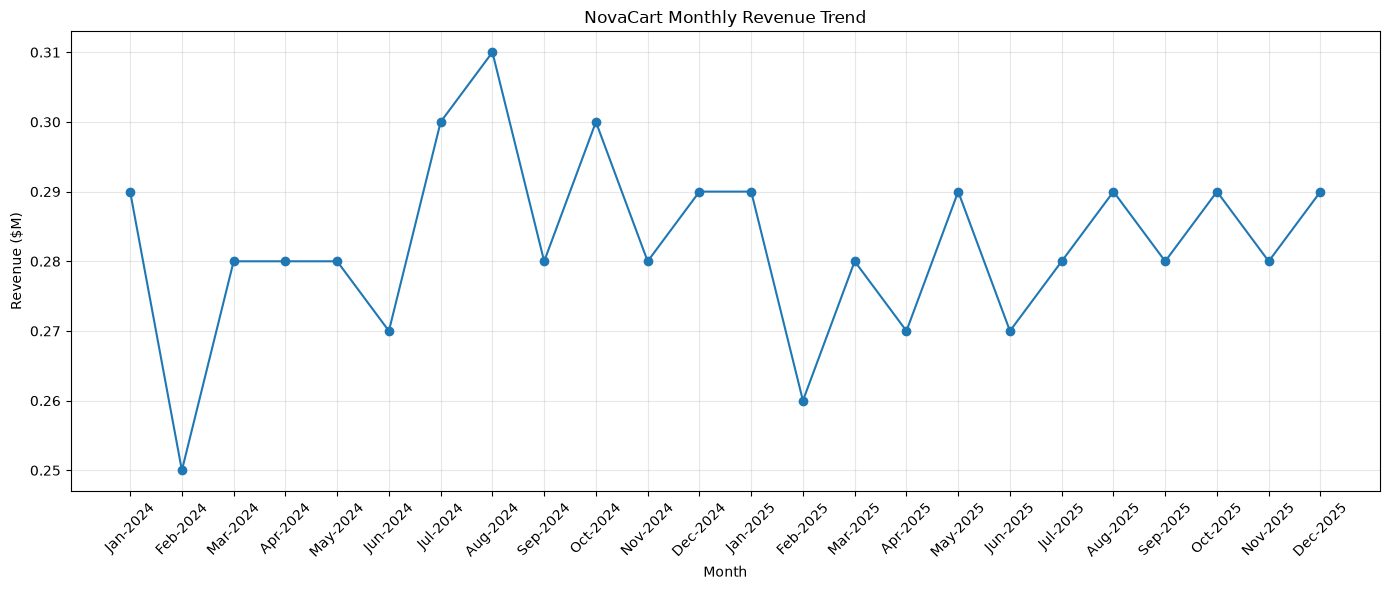

In [98]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))

plt.plot(
    monthly_kpi["Month"],
    monthly_kpi["Revenue_USD_M"],
    marker="o"
)

plt.title("NovaCart Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue ($M)")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# ==> Category Revenue vs Profit <==

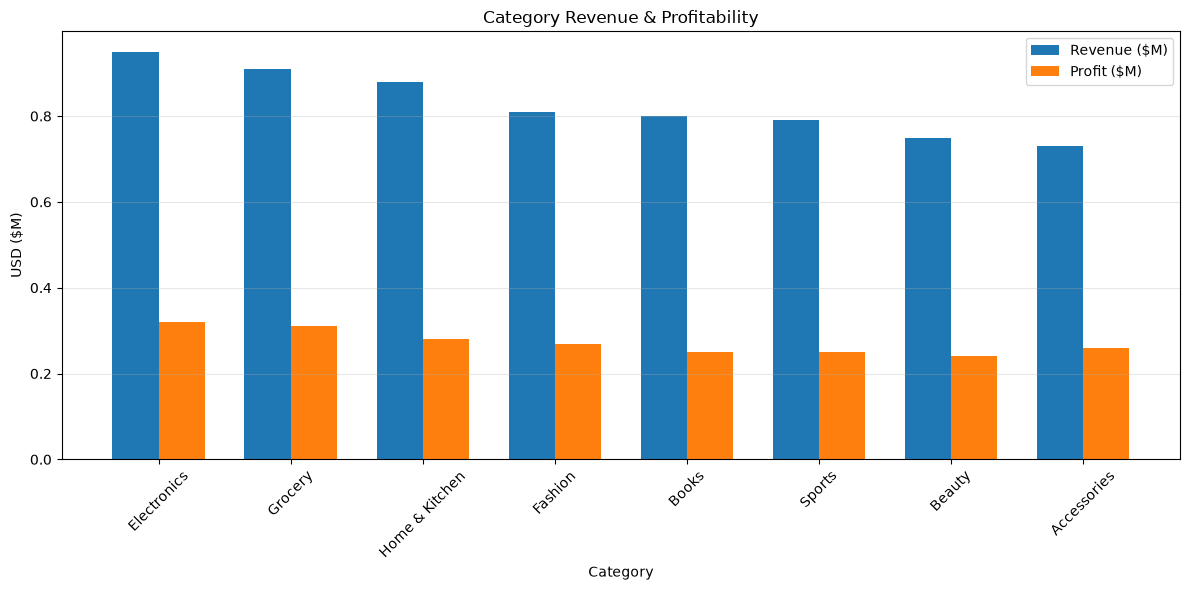

In [99]:
import matplotlib.pyplot as plt
import numpy as np

category_plot = category_ana.sort_values(
    "Revenue_USD_M",
    ascending=False
)

x = np.arange(len(category_plot))
width = 0.35

plt.figure(figsize=(12, 6))

plt.bar(
    x - width/2,
    category_plot["Revenue_USD_M"],
    width,
    label="Revenue ($M)"
)

plt.bar(
    x + width/2,
    category_plot["profit_USD_M"],
    width,
    label="Profit ($M)"
)

plt.title("Category Revenue & Profitability")
plt.xlabel("Category")
plt.ylabel("USD ($M)")
plt.xticks(x, category_plot["category"], rotation=45)
plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

# ==> Regional Revenue vs Profit <== 

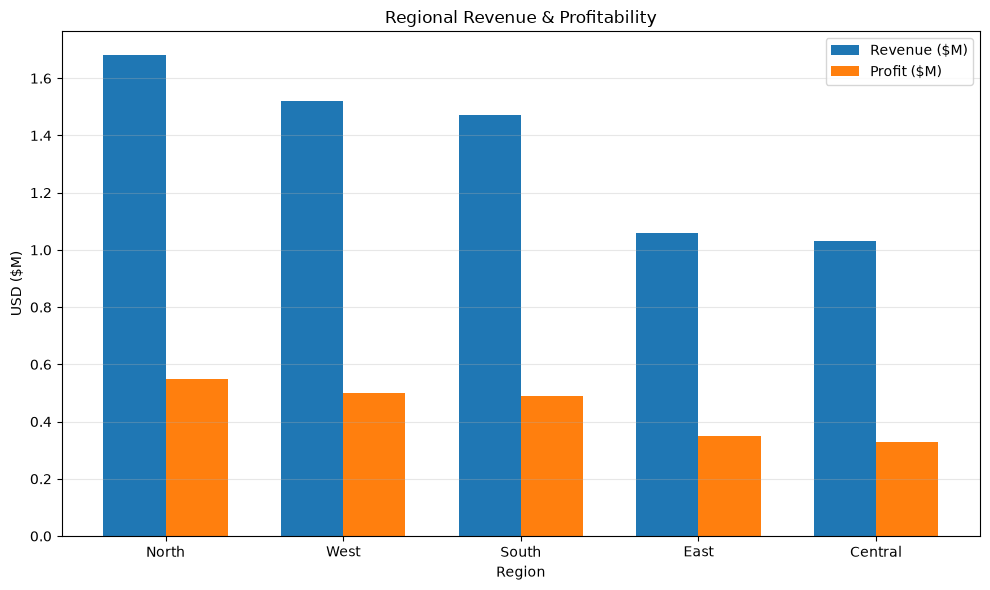

In [100]:
import matplotlib.pyplot as plt
import numpy as np

region_plot = regional_analysis.sort_values(
    "Revenue_USD_M",
    ascending=False
)

x = np.arange(len(region_plot))
width = 0.35

plt.figure(figsize=(10, 6))

plt.bar(
    x - width/2,
    region_plot["Revenue_USD_M"],
    width,
    label="Revenue ($M)"
)

plt.bar(
    x + width/2,
    region_plot["profit_USD_M"],
    width,
    label="Profit ($M)"
)

plt.title("Regional Revenue & Profitability")
plt.xlabel("Region")
plt.ylabel("USD ($M)")
plt.xticks(x, region_plot["region"])
plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

# ==> Customer Purchase Frequency <==

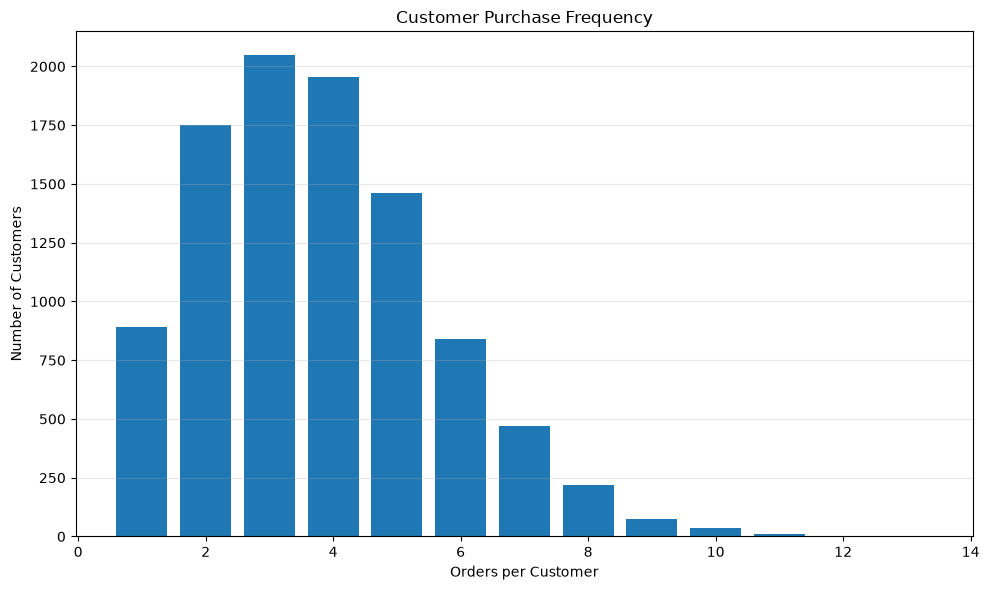

In [101]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.bar(
    purchase_frequency_dis["Orders_Per_Customer"],
    purchase_frequency_dis["Customer_Count"]
)

plt.title("Customer Purchase Frequency")
plt.xlabel("Orders per Customer")
plt.ylabel("Number of Customers")

plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [102]:
print

<function print(*args, sep=' ', end='\n', file=None, flush=False)>